Original Source Shape: (1000, 3)


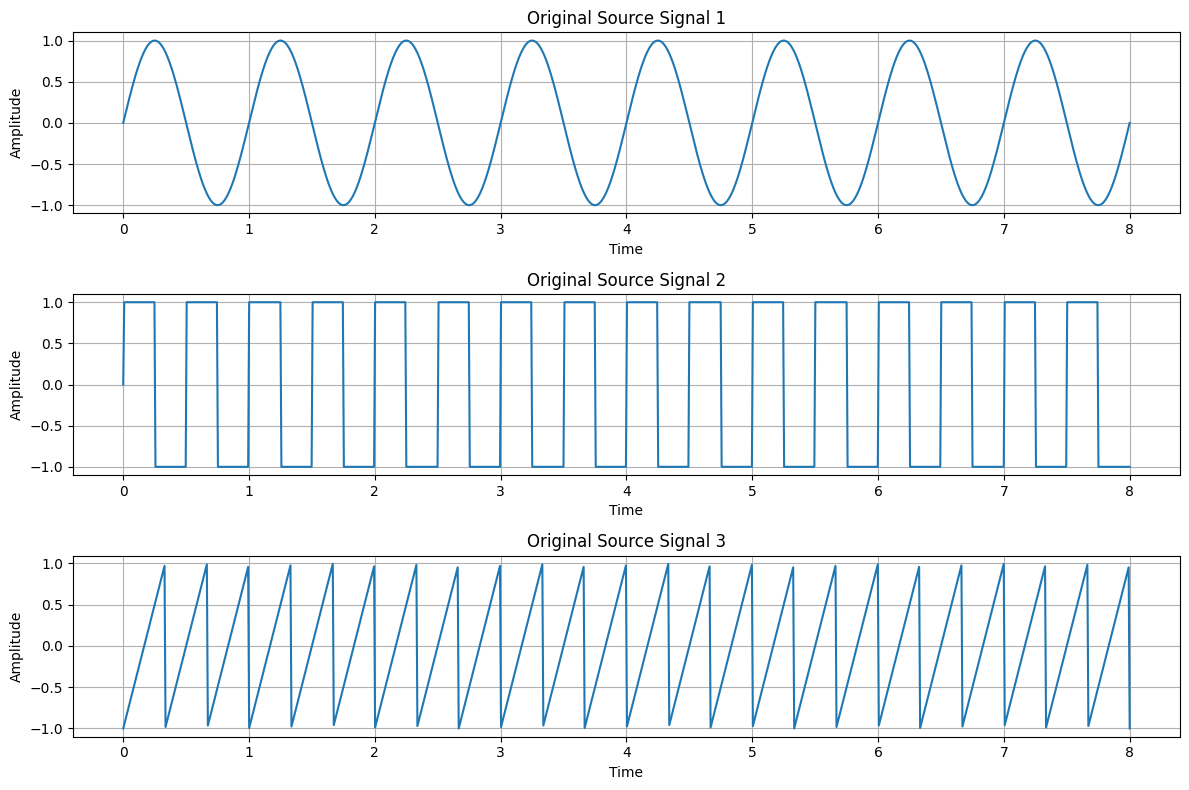


Mixing Matrix:
[[1 2 1]
 [2 1 3]
 [3 2 2]]

Mixed Data Shape: (1000, 3)


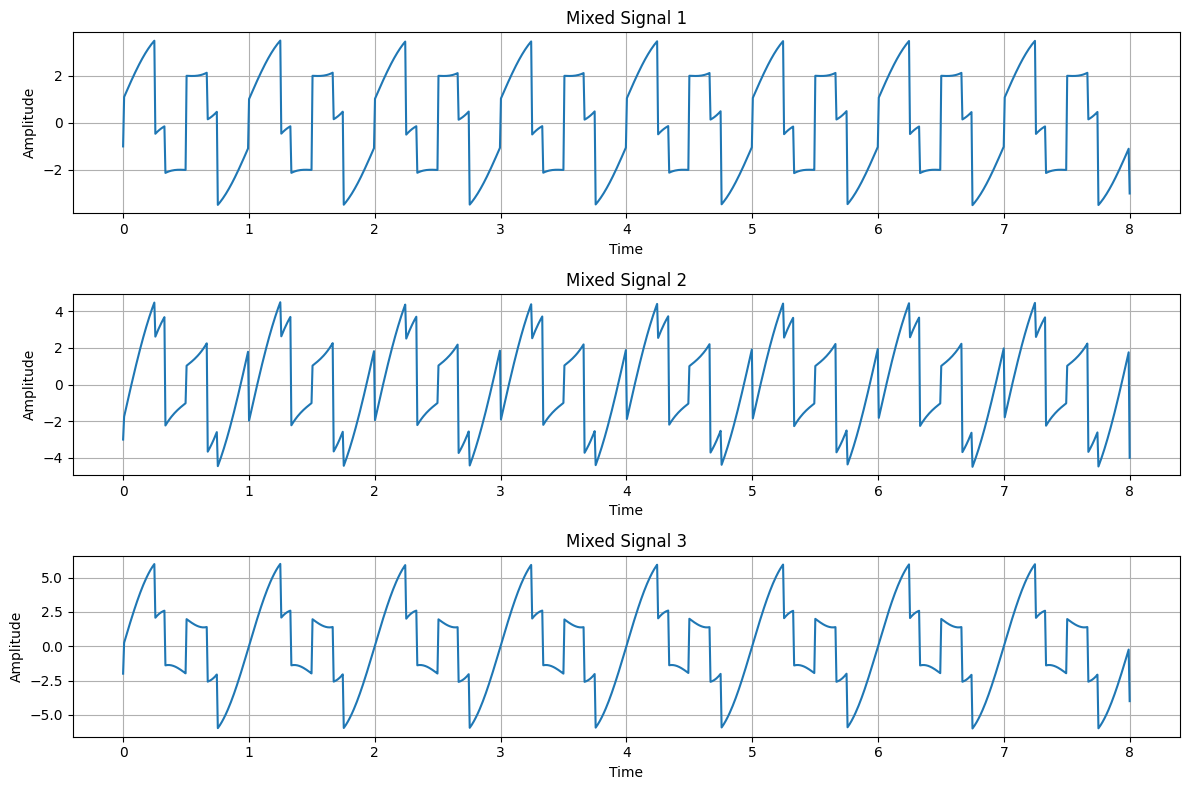


ICA Recovered Shape: (1000, 3)


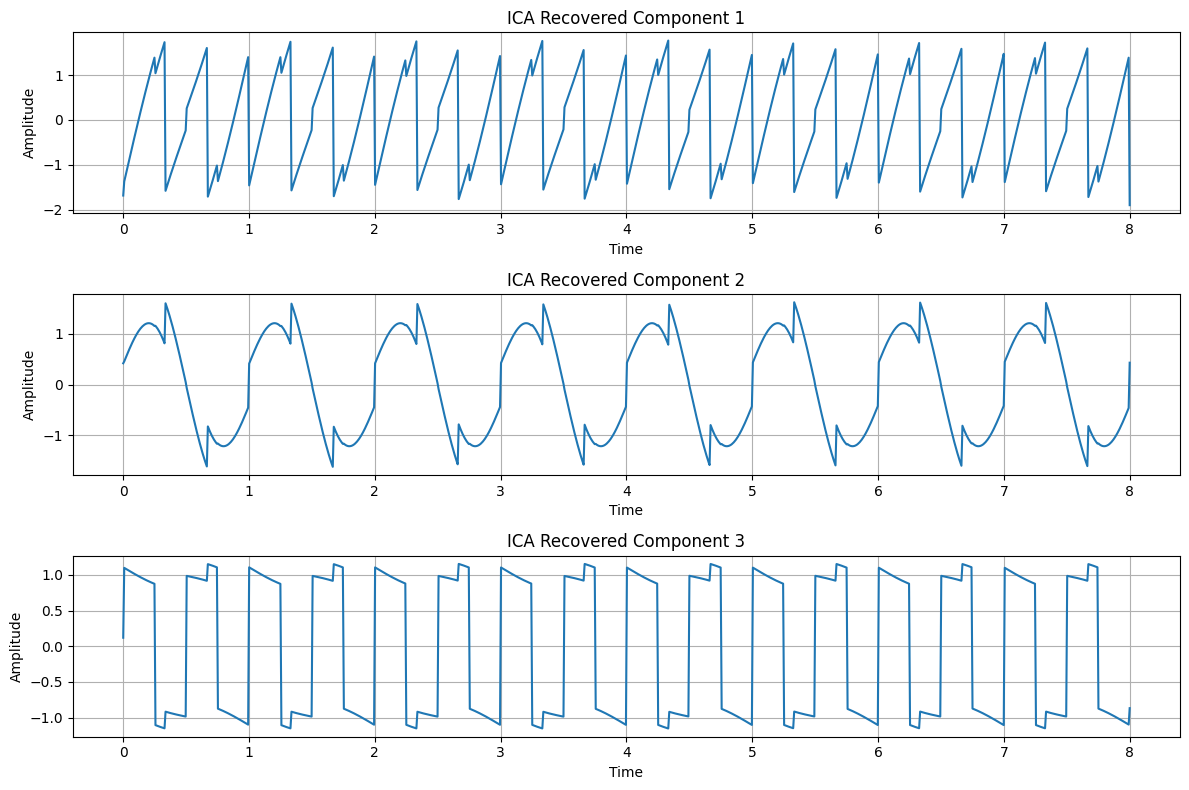


PCA Recovered Shape: (1000, 3)


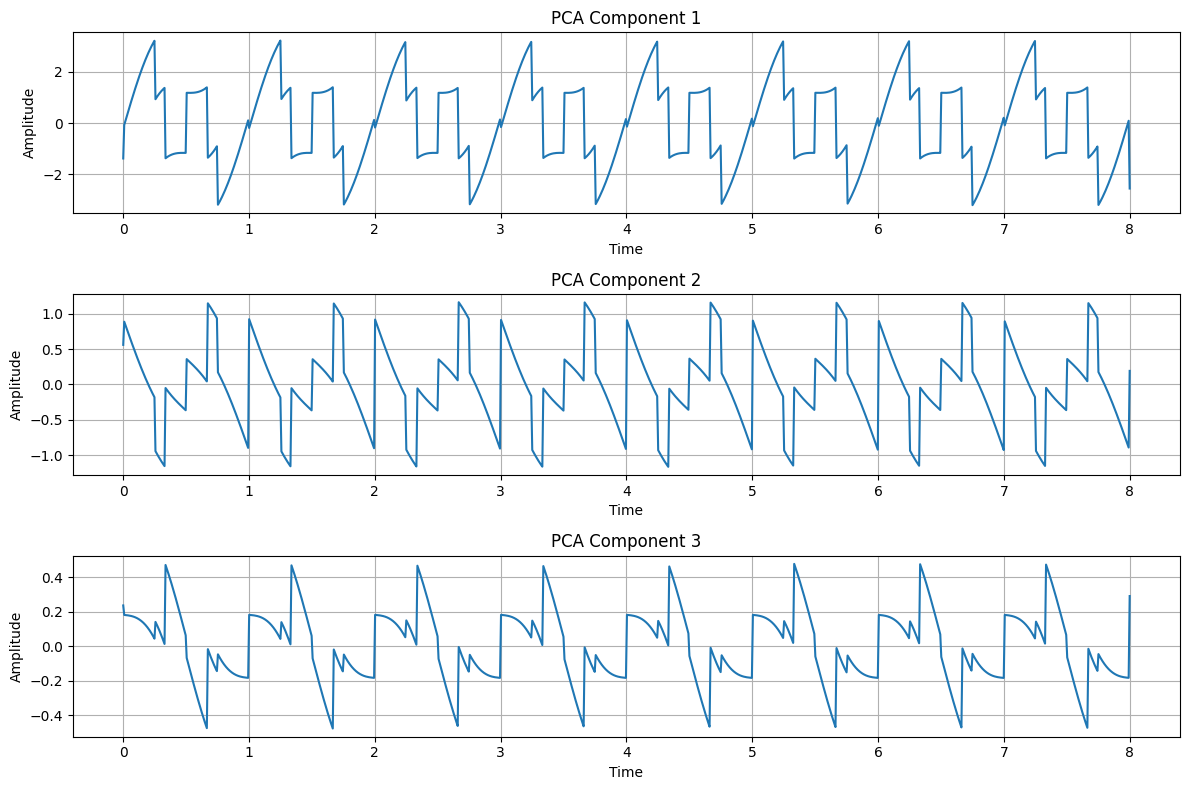

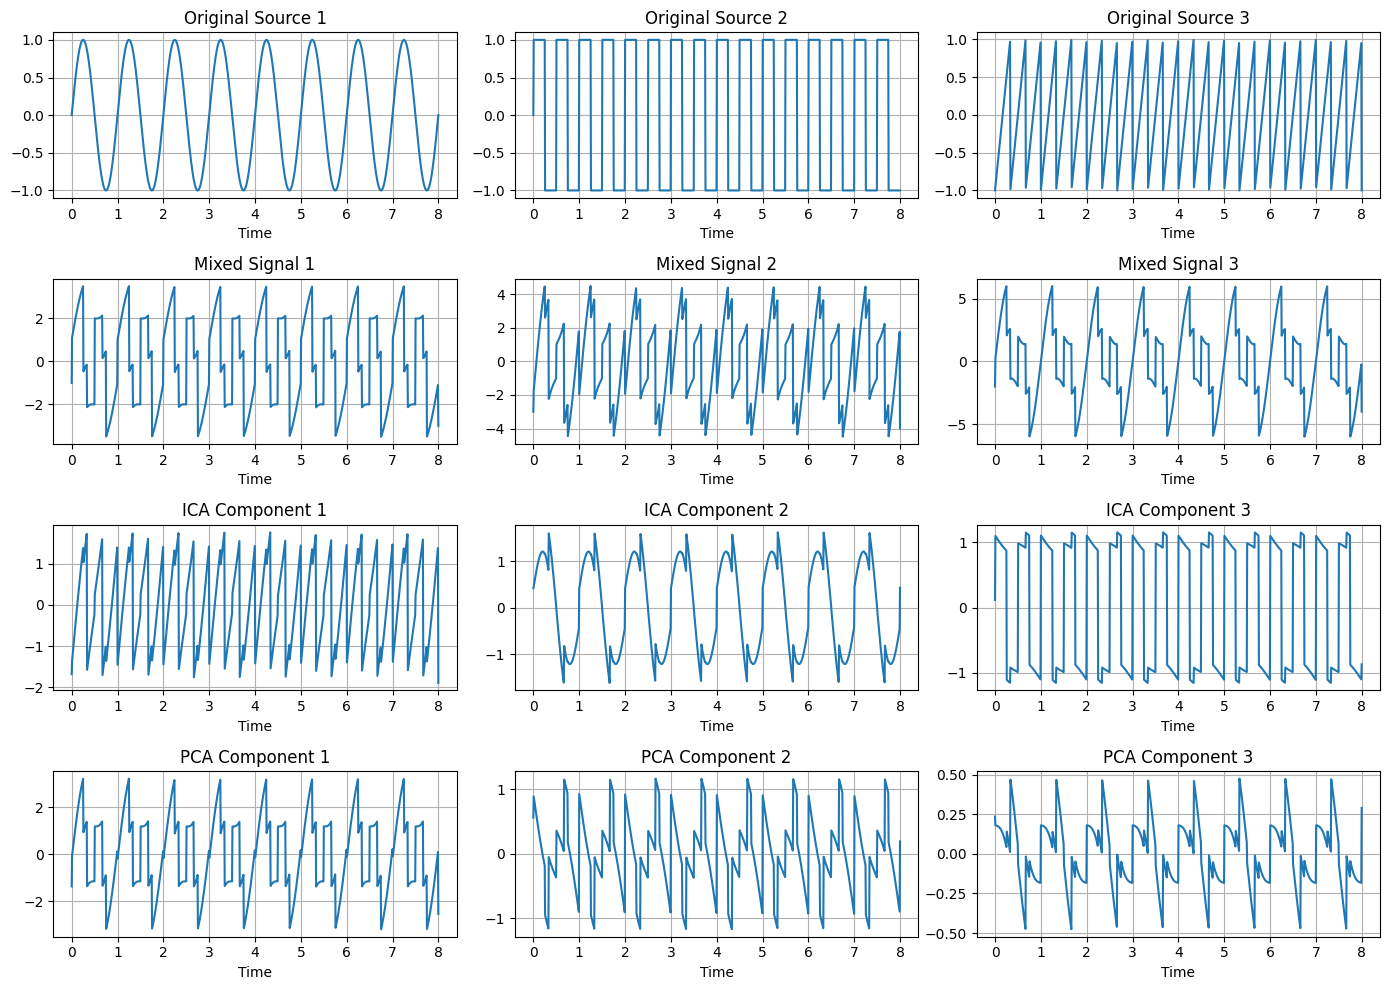


Correlation Between Original and ICA Components:
[[ 0.239  0.97  -0.04 ]
 [ 0.075  0.021  0.997]
 [ 0.948 -0.242 -0.208]]

Correlation Between Original and PCA Components:
[[ 0.584 -0.344  0.736]
 [ 0.648  0.742 -0.17 ]
 [ 0.391 -0.675 -0.626]]


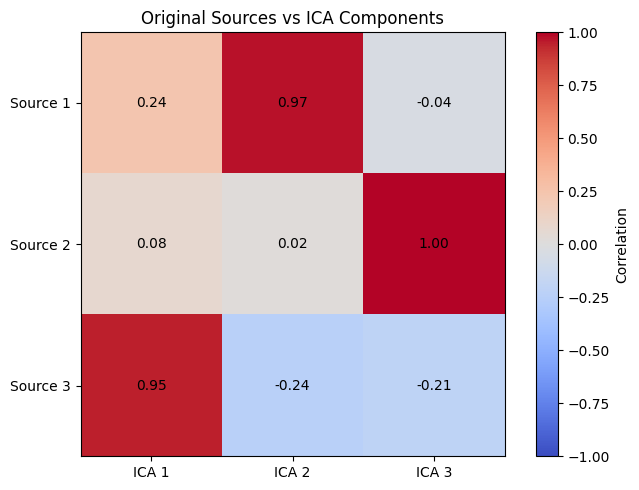

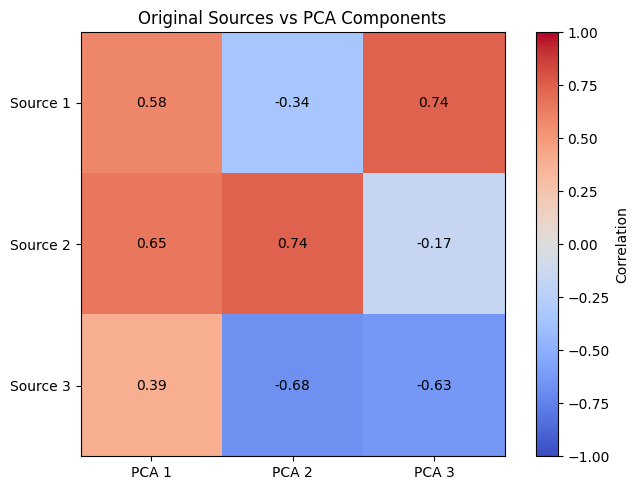


Experiment 22 Completed Successfully!
Three original signals were generated.
Signals were mixed using a mixing matrix.
ICA was applied to recover independent components.
PCA was applied for comparison.
Recovery quality was evaluated using correlation.


In [26]:

# EXPERIMENT 22: INDEPENDENT COMPONENT ANALYSIS AND COMPONENT VISUALIZATION

import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import sawtooth
from sklearn.decomposition import FastICA, PCA
from sklearn.preprocessing import StandardScaler

# --------------------------------------------------
# 1. GENERATE THREE SOURCE SIGNALS
# --------------------------------------------------

np.random.seed(42)

n_samples = 1000
time = np.linspace(0, 8, n_samples)

# Source 1: Sine wave
s1 = np.sin(2 * np.pi * 1 * time)

# Source 2: Square wave
s2 = np.sign(np.sin(2 * np.pi * 2 * time))

# Source 3: Sawtooth wave
s3 = sawtooth(2 * np.pi * 3 * time)

# Combine source signals
S = np.c_[s1, s2, s3]

print("Original Source Shape:", S.shape)

# --------------------------------------------------
# 2. VISUALIZE ORIGINAL SOURCE SIGNALS
# --------------------------------------------------

plt.figure(figsize=(12, 8))

for i in range(3):
    plt.subplot(3, 1, i + 1)
    plt.plot(time, S[:, i])
    plt.title(f"Original Source Signal {i+1}")
    plt.xlabel("Time")
    plt.ylabel("Amplitude")
    plt.grid(True)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 3. MIX THE SOURCE SIGNALS
# --------------------------------------------------

# Random mixing matrix
A = np.array([
    [1, 2, 1],
    [2, 1, 3],
    [3, 2, 2]
])

# Mix the signals
X = S @ A.T

print("\nMixing Matrix:")
print(A)

print("\nMixed Data Shape:", X.shape)

# --------------------------------------------------
# 4. VISUALIZE MIXED SIGNALS
# --------------------------------------------------

plt.figure(figsize=(12, 8))

for i in range(3):
    plt.subplot(3, 1, i + 1)
    plt.plot(time, X[:, i])
    plt.title(f"Mixed Signal {i+1}")
    plt.xlabel("Time")
    plt.ylabel("Amplitude")
    plt.grid(True)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 5. STANDARDIZE MIXED SIGNALS
# --------------------------------------------------

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --------------------------------------------------
# 6. APPLY INDEPENDENT COMPONENT ANALYSIS (ICA)
# --------------------------------------------------

ica = FastICA(
    n_components=3,
    random_state=42,
    max_iter=1000,
    tol=0.001
)

S_ica = ica.fit_transform(X_scaled)

print("\nICA Recovered Shape:", S_ica.shape)

# --------------------------------------------------
# 7. VISUALIZE ICA RECOVERED SIGNALS
# --------------------------------------------------

plt.figure(figsize=(12, 8))

for i in range(3):
    plt.subplot(3, 1, i + 1)
    plt.plot(time, S_ica[:, i])
    plt.title(f"ICA Recovered Component {i+1}")
    plt.xlabel("Time")
    plt.ylabel("Amplitude")
    plt.grid(True)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. APPLY PCA FOR COMPARISON
# --------------------------------------------------

pca = PCA(n_components=3)

S_pca = pca.fit_transform(X_scaled)

print("\nPCA Recovered Shape:", S_pca.shape)

# --------------------------------------------------
# 9. VISUALIZE PCA COMPONENTS
# --------------------------------------------------

plt.figure(figsize=(12, 8))

for i in range(3):
    plt.subplot(3, 1, i + 1)
    plt.plot(time, S_pca[:, i])
    plt.title(f"PCA Component {i+1}")
    plt.xlabel("Time")
    plt.ylabel("Amplitude")
    plt.grid(True)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 10. COMPARE ORIGINAL, MIXED, ICA AND PCA SIGNALS
# --------------------------------------------------

plt.figure(figsize=(14, 10))

for i in range(3):

    plt.subplot(4, 3, i + 1)
    plt.plot(time, S[:, i])
    plt.title(f"Original Source {i+1}")

    plt.subplot(4, 3, i + 4)
    plt.plot(time, X[:, i])
    plt.title(f"Mixed Signal {i+1}")

    plt.subplot(4, 3, i + 7)
    plt.plot(time, S_ica[:, i])
    plt.title(f"ICA Component {i+1}")

    plt.subplot(4, 3, i + 10)
    plt.plot(time, S_pca[:, i])
    plt.title(f"PCA Component {i+1}")

for ax in plt.gcf().axes:
    ax.set_xlabel("Time")
    ax.grid(True)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 11. MEASURE RECOVERY QUALITY USING CORRELATION
# --------------------------------------------------

ica_corr = np.corrcoef(S.T, S_ica.T)[:3, 3:]

pca_corr = np.corrcoef(S.T, S_pca.T)[:3, 3:]

print("\nCorrelation Between Original and ICA Components:")
print(np.round(ica_corr, 3))

print("\nCorrelation Between Original and PCA Components:")
print(np.round(pca_corr, 3))

# --------------------------------------------------
# 12. DISPLAY CORRELATION HEATMAPS
# --------------------------------------------------

plt.figure(figsize=(7, 5))

plt.imshow(ica_corr, cmap='coolwarm', vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(
    range(3),
    ['ICA 1', 'ICA 2', 'ICA 3']
)

plt.yticks(
    range(3),
    ['Source 1', 'Source 2', 'Source 3']
)

plt.title("Original Sources vs ICA Components")

for i in range(3):
    for j in range(3):
        plt.text(
            j, i,
            f"{ica_corr[i, j]:.2f}",
            ha='center',
            va='center'
        )

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 13. PCA CORRELATION HEATMAP
# --------------------------------------------------

plt.figure(figsize=(7, 5))

plt.imshow(pca_corr, cmap='coolwarm', vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(
    range(3),
    ['PCA 1', 'PCA 2', 'PCA 3']
)

plt.yticks(
    range(3),
    ['Source 1', 'Source 2', 'Source 3']
)

plt.title("Original Sources vs PCA Components")

for i in range(3):
    for j in range(3):
        plt.text(
            j, i,
            f"{pca_corr[i, j]:.2f}",
            ha='center',
            va='center'
        )

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 14. FINAL RESULT
# --------------------------------------------------

print("\nExperiment 22 Completed Successfully!")
print("Three original signals were generated.")
print("Signals were mixed using a mixing matrix.")
print("ICA was applied to recover independent components.")
print("PCA was applied for comparison.")
print("Recovery quality was evaluated using correlation.")
